# **Linear Regression: Property Price Prediction**

In [ ]:
import pandas as pd

df = pd.read_csv("/content/train.csv")

df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [ ]:
print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nFirst 5 Records:")
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum().sort_values(ascending=False).head(15))

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Shape:
(1460, 81)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  Over

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



Missing Values:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
GarageYrBlt       81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtCond          37
dtype: int64

Duplicate Rows:
0


In [ ]:
selected_features = [
    "GrLivArea",
    "OverallQual",
    "YearBuilt",
    "FullBath",
    "GarageCars"
]

target = "SalePrice"

model_df = df[selected_features + [target]].copy()

model_df.head()

,GrLivArea,OverallQual,YearBuilt,FullBath,GarageCars,SalePrice
0,1710,7,2003,2,2,208500
1,1262,6,1976,2,2,181500
2,1786,7,2001,2,2,223500
3,1717,7,1915,1,3,140000
4,2198,8,2000,2,3,250000


In [ ]:
model_df.info()
model_df.isnull().sum()
model_df = model_df.dropna()
print("Final Dataset Shape:", model_df.shape)

X = model_df[selected_features]
y = model_df[target]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   GrLivArea    1460 non-null   int64
 1   OverallQual  1460 non-null   int64
 2   YearBuilt    1460 non-null   int64
 3   FullBath     1460 non-null   int64
 4   GarageCars   1460 non-null   int64
 5   SalePrice    1460 non-null   int64
dtypes: int64(6)
memory usage: 68.6 KB
Final Dataset Shape: (1460, 6)


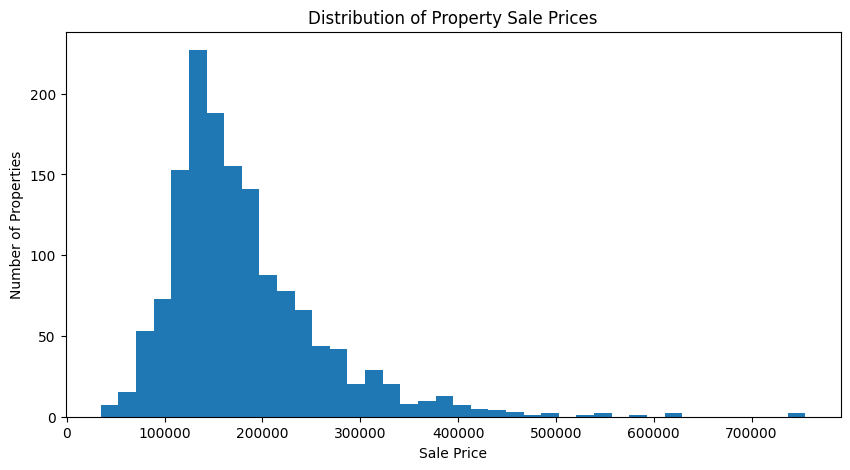

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(y, bins=40)

plt.title("Distribution of Property Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Number of Properties")

plt.show()

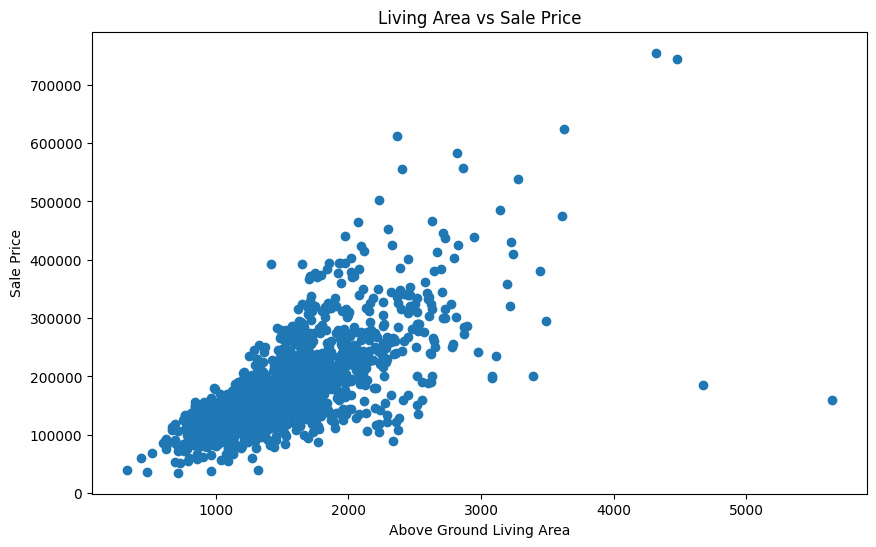

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
    model_df["GrLivArea"],
    model_df["SalePrice"]
)

plt.title("Living Area vs Sale Price")
plt.xlabel("Above Ground Living Area")
plt.ylabel("Sale Price")

plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (1168, 5)
Testing Data Shape: (292, 5)


**Model Training**

In [ ]:
model = LinearRegression()

model.fit(X_train, y_train)

LinearRegression()

In [ ]:
coefficients = pd.DataFrame({
    "Feature": selected_features,
    "Coefficient": model.coef_
})

coefficients


,Feature,Coefficient
0,GrLivArea,58.768133
1,OverallQual,22457.479148
2,YearBuilt,429.483551
3,FullBath,-8939.508399
4,GarageCars,16871.640095


In [ ]:
print("Intercept:", model.intercept_)

Intercept: -908255.2530580264


In [ ]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred,
    "Difference": y_test.values - y_pred
})

results.head(10)

,Actual Price,Predicted Price,Difference
0,154500,140262.330110,14237.669890
1,325000,297749.089197,27250.910803
2,115000,116864.357898,-1864.357898
3,159000,176348.532390,-17348.532390
4,315500,283775.825117,31724.174883
5,75500,56600.641328,18899.358672
6,311500,221352.410163,90147.589837
7,146000,177438.750757,-31438.750757
8,84500,55741.674226,28758.325774
9,135500,133468.625851,2031.374149


In [ ]:
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error: {mae:,.2f}")
print(f"Root Mean Squared Error: {rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

Mean Absolute Error: 27,576.24
Root Mean Squared Error: 42,340.94
R² Score: 0.7663


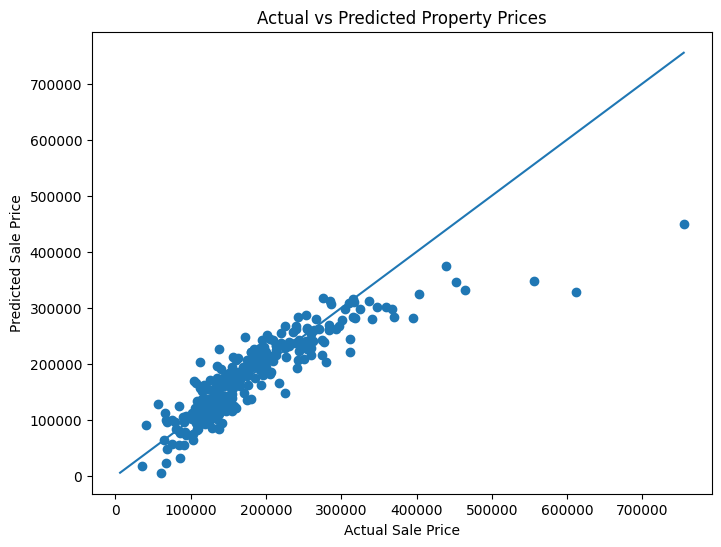

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")

plt.title("Actual vs Predicted Property Prices")

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value]
)

plt.show()

In [ ]:
def predict_property_price(
    living_area,
    overall_quality,
    year_built,
    full_bathrooms,
    garage_capacity
):

    input_data = pd.DataFrame(
        [[
            living_area,
            overall_quality,
            year_built,
            full_bathrooms,
            garage_capacity
        ]],
        columns=selected_features
    )

    prediction = model.predict(input_data)[0]

    return round(prediction, 2)

In [ ]:
!pip install -q gradio

In [ ]:
import gradio as gr

def property_inference(
    living_area,
    overall_quality,
    year_built,
    full_bathrooms,
    garage_capacity
):

    predicted_price = predict_property_price(
        living_area,
        overall_quality,
        year_built,
        full_bathrooms,
        garage_capacity
    )

    return {
        "Predicted Property Value": f"${predicted_price:,.2f}",
        "Model": "Linear Regression",
        "Inference Status": "Prediction Generated Successfully"
    }



with gr.Blocks(title="Property Value Estimation") as demo:

    gr.Markdown("""
    # Property Value Estimation
    ### Machine Learning Inference Demonstration

    Enter the property characteristics below to generate an estimated
    property value using the trained Linear Regression model.
    """)

    with gr.Row():

        with gr.Column():

            living_area = gr.Number(
                label="Above Ground Living Area (sq. ft.)",
                value=1500
            )

            overall_quality = gr.Slider(
                minimum=1,
                maximum=10,
                value=6,
                step=1,
                label="Overall Quality Rating"
            )

            year_built = gr.Number(
                label="Year Built",
                value=2000
            )

        with gr.Column():

            full_bathrooms = gr.Slider(
                minimum=0,
                maximum=5,
                value=2,
                step=1,
                label="Number of Full Bathrooms"
            )

            garage_capacity = gr.Slider(
                minimum=0,
                maximum=5,
                value=2,
                step=1,
                label="Garage Capacity"
            )

    predict_button = gr.Button(
        "Run Prediction",
        variant="primary"
    )

    output = gr.JSON(
        label="Inference Result"
    )

    predict_button.click(
        fn=property_inference,
        inputs=[
            living_area,
            overall_quality,
            year_built,
            full_bathrooms,
            garage_capacity
        ],
        outputs=output
    )

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://96c7037c580cd0253f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
